countries (177, 169) EPSG:4326
places (243, 138) EPSG:4326
borders (331, 41) EPSG:4326
states (51, 122) EPSG:4326
['featurecla', 'scalerank', 'LABELRANK', 'SOVEREIGNT', 'SOV_A3', 'ADM0_DIF', 'LEVEL', 'TYPE', 'TLC', 'ADMIN', 'ADM0_A3', 'GEOU_DIF', 'GEOUNIT', 'GU_A3', 'SU_DIF', 'SUBUNIT', 'SU_A3', 'BRK_DIFF', 'NAME', 'NAME_LONG', 'BRK_A3', 'BRK_NAME', 'BRK_GROUP', 'ABBREV', 'POSTAL', 'FORMAL_EN', 'FORMAL_FR', 'NAME_CIAWF', 'NOTE_ADM0', 'NOTE_BRK', 'NAME_SORT', 'NAME_ALT', 'MAPCOLOR7', 'MAPCOLOR8', 'MAPCOLOR9', 'MAPCOLOR13', 'POP_EST', 'POP_RANK', 'POP_YEAR', 'GDP_MD', 'GDP_YEAR', 'ECONOMY', 'INCOME_GRP', 'FIPS_10', 'ISO_A2', 'ISO_A2_EH', 'ISO_A3', 'ISO_A3_EH', 'ISO_N3', 'ISO_N3_EH', 'UN_A3', 'WB_A2', 'WB_A3', 'WOE_ID', 'WOE_ID_EH', 'WOE_NOTE', 'ADM0_ISO', 'ADM0_DIFF', 'ADM0_TLC', 'ADM0_A3_US', 'ADM0_A3_FR', 'ADM0_A3_RU', 'ADM0_A3_ES', 'ADM0_A3_CN', 'ADM0_A3_TW', 'ADM0_A3_IN', 'ADM0_A3_NP', 'ADM0_A3_PK', 'ADM0_A3_DE', 'ADM0_A3_GB', 'ADM0_A3_BR', 'ADM0_A3_IL', 'ADM0_A3_PS', 'ADM0_A3_SA', '

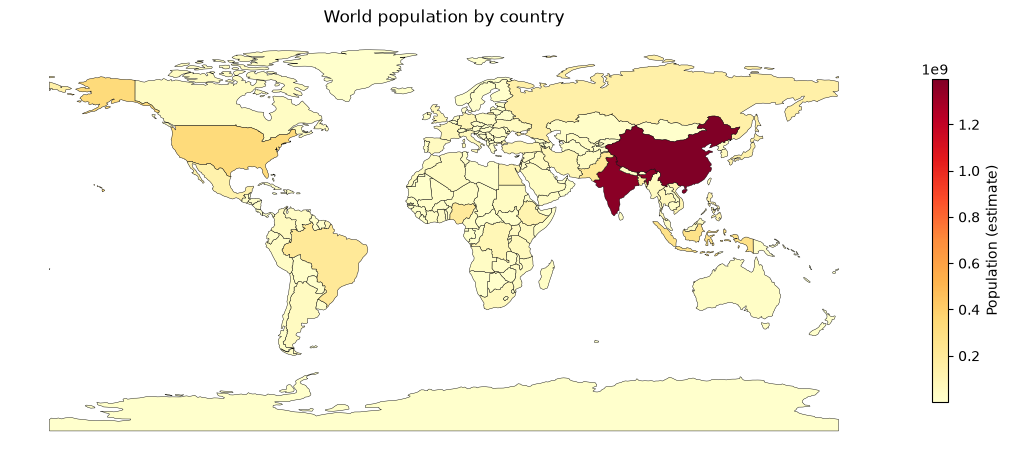

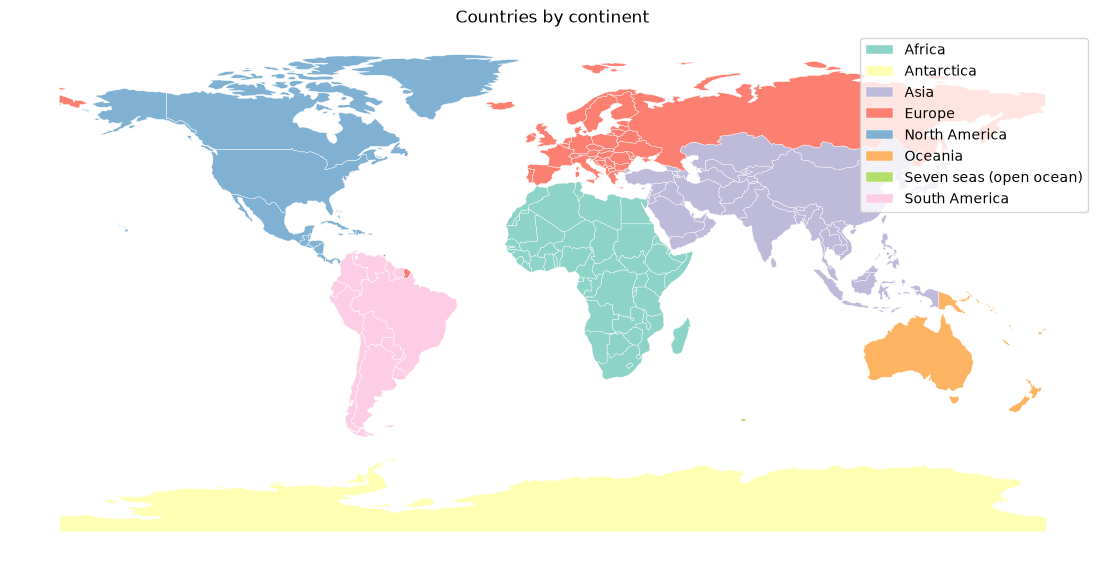

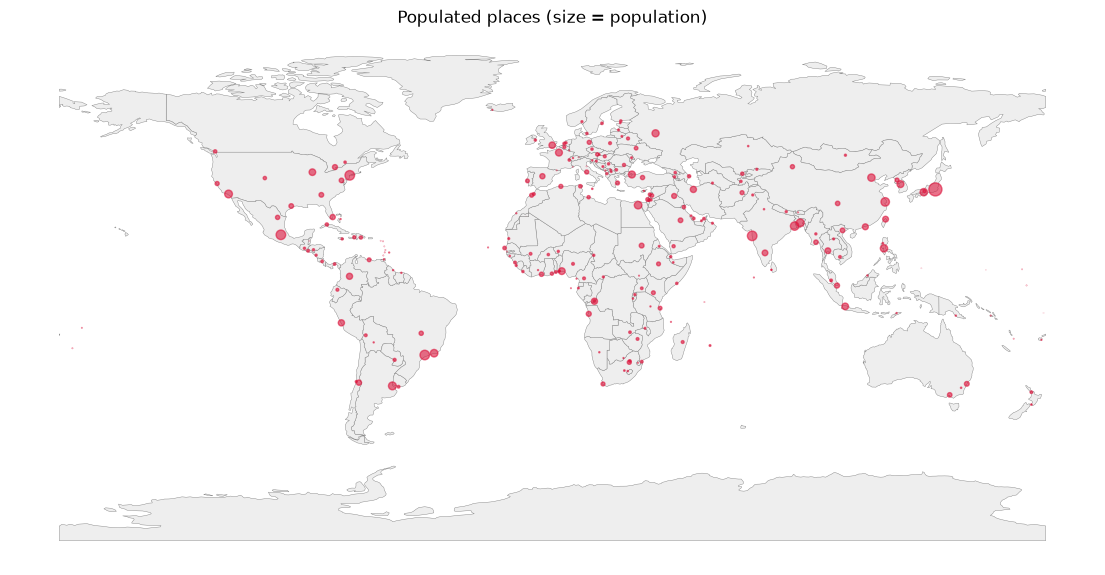

/usr/local/python/3.14.2/lib/python3.14/site-packages/folium/raster_layers.py:130: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


In [10]:
import geopandas as gpd
import folium
import matplotlib.pyplot as plt

# Path to the folder you uploaded (adjust if it sits in a subfolder)
DATA = "110m_cultural/"

# ---------- Load the main datasets ----------
countries = gpd.read_file(DATA + "ne_110m_admin_0_countries.shp")
places    = gpd.read_file(DATA + "ne_110m_populated_places.shp")
borders   = gpd.read_file(DATA + "ne_110m_admin_0_boundary_lines_land.shp")
states    = gpd.read_file(DATA + "ne_110m_admin_1_states_provinces.shp")

for name, gdf in [("countries", countries), ("places", places),
                  ("borders", borders), ("states", states)]:
    print(name, gdf.shape, gdf.crs)

print(countries.columns.tolist())   # check column names (NAME, POP_EST, CONTINENT, ...)
countries.head()

# ---------- 1. Countries coloured by population ----------
fig, ax = plt.subplots(figsize=(14, 7))
countries.plot(ax=ax, column="POP_EST", cmap="YlOrRd", legend=True,
               edgecolor="black", linewidth=0.3,
               legend_kwds={"label": "Population (estimate)", "shrink": 0.6})
ax.set_title("World population by country")
ax.set_axis_off()
plt.show()

# ---------- 2. Countries coloured by continent ----------
fig, ax = plt.subplots(figsize=(14, 7))
countries.plot(ax=ax, column="CONTINENT", cmap="Set3", legend=True,
               edgecolor="white", linewidth=0.3)
ax.set_title("Countries by continent")
ax.set_axis_off()
plt.show()

# ---------- 3. Populated places on top of borders ----------
fig, ax = plt.subplots(figsize=(14, 7))
countries.plot(ax=ax, color="#eeeeee", edgecolor="grey", linewidth=0.3)
places.plot(ax=ax, color="crimson", alpha=0.6,
            markersize=places["POP_MAX"] / 400000)
ax.set_title("Populated places (size = population)")
ax.set_axis_off()
plt.show()

# ---------- 4. Interactive map (folium) ----------
m = folium.Map(location=[20, 0], zoom_start=2, tiles="CartoDB positron")

folium.Choropleth(
    geo_data=countries.__geo_interface__,
    data=countries,
    columns=["ADM0_A3", "POP_EST"],
    key_on="feature.properties.ADM0_A3",
    fill_color="YlOrRd",
    fill_opacity=0.7,
    line_opacity=0.3,
    legend_name="Population (estimate)",
).add_to(m)

folium.GeoJson(
    countries[["NAME", "POP_EST", "CONTINENT", "geometry"]],
    style_function=lambda f: {"fillOpacity": 0, "weight": 0},
    tooltip=folium.GeoJsonTooltip(fields=["NAME", "CONTINENT", "POP_EST"]),
).add_to(m)

for _, row in places.iterrows():
    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=3, color="blue", fill=True, fill_opacity=0.7,
        tooltip=f"{row['NAME']} ({int(row['POP_MAX']):,})",
    ).add_to(m)

m.save("world_map.html")
m   # displays in a notebook